In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv('insurance.csv')
df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


In [2]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [3]:
df.tail()

,age,sex,bmi,children,smoker,region,charges
1333,50,male,30.97,3,no,northwest,10600.5483
1334,18,female,31.92,0,no,northeast,2205.9808
1335,18,female,36.85,0,no,southeast,1629.8335
1336,21,female,25.80,0,no,southwest,2007.9450
1337,61,female,29.07,0,yes,northwest,29141.3603


In [5]:
df.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='str')

In [6]:
df.shape

(1338, 7)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


In [7]:
df.isnull()

,age,sex,bmi,children,smoker,region,charges
0,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...
1333,False,False,False,False,False,False,False
1334,False,False,False,False,False,False,False
1335,False,False,False,False,False,False,False
1336,False,False,False,False,False,False,False


In [8]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [9]:
df.isnull().sum().sum()

np.int64(0)

In [10]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [11]:
df.duplicated().sum()

np.int64(1)

In [12]:
df = df.drop_duplicates()

In [13]:
df.duplicated().sum()


np.int64(0)

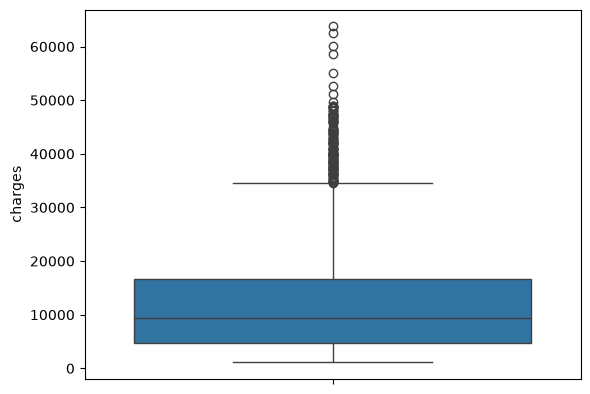

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.boxplot(y=df['charges'])
plt.show()

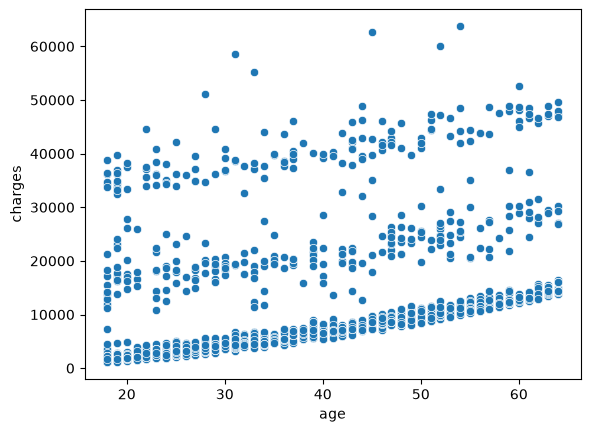

In [15]:
sns.scatterplot(x='age', y='charges', data=df)
plt.show()

In [16]:
df.describe()

,age,bmi,children,charges
count,1337.000000,1337.000000,1337.000000,1337.000000
mean,39.222139,30.663452,1.095737,13279.121487
std,14.044333,6.100468,1.205571,12110.359656
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.290000,0.000000,4746.344000
50%,39.000000,30.400000,1.000000,9386.161300
75%,51.000000,34.700000,2.000000,16657.717450
max,64.000000,53.130000,5.000000,63770.428010


In [17]:
Q1 = df['charges'].quantile(0.25)
Q3 = df['charges'].quantile(0.75)

IQR = Q3 - Q1

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("IQR:", IQR)
print("Lower Bound:", lower)
print("Upper Bound:", upper)

Q1: 4746.344
Q3: 16657.71745
IQR: 11911.37345
IQR: 11911.37345
Lower Bound: -13120.716174999998
Upper Bound: 34524.777625


In [18]:
from scipy import stats
z_score = np.abs(stats.zscore(df['charges']))
df = df[z_score < 2]

In [19]:
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm

formula = 'charges ~ age + bmi + children + C(sex) + C(smoker) + C(region)'

model = ols(formula, df).fit()

aov_table = anova_lm(model)

print(aov_table)

               df        sum_sq       mean_sq            F         PR(>F)
C(sex)        1.0  1.145224e+05  1.145224e+05     0.004255   9.480042e-01
C(smoker)     1.0  3.704187e+10  3.704187e+10  1376.111218  2.452057e-202
C(region)     3.0  7.261667e+07  2.420556e+07     0.899240   4.409334e-01
age           1.0  1.296763e+10  1.296763e+10   481.749469   2.845381e-90
bmi           1.0  8.231080e+08  8.231080e+08    30.578595   3.917994e-08
children      1.0  2.815222e+08  2.815222e+08    10.458596   1.253485e-03
Residual   1221.0  3.286662e+10  2.691778e+07          NaN            NaN


In [20]:
aov_table['PR(>F)'] < 0.05

C(sex)       False
C(smoker)     True
C(region)    False
age           True
bmi           True
children      True
Residual     False
Name: PR(>F), dtype: bool

In [21]:
df = df.drop(columns=['sex', 'region'])

In [26]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

df['sex'] = le.fit_transform(df['sex'])
df['smoker'] = le.fit_transform(df['smoker'])
df['region'] = le.fit_transform(df['region'])

KeyError: 'sex'